In [1]:
# copy code (Eda_clustering)
import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf
from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.layers import LSTM, Dropout, Dense
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input

from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

import pickle 
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

import prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation
from prophet.diagnostics import performance_metrics
from prophet.plot import add_changepoints_to_plot
from prophet.plot import plot_cross_validation_metric
from prophet.plot import plot_plotly
from prophet.serialize import model_to_json
import plotly.graph_objs as go

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

In [3]:
### Visualization 2020 to 2023

df1 = read_obj("Project_final_20_23")
df = read_obj("Project_final_20_23")

In [4]:
# Extract data with pt
filtered_columns = [col for col in df1.columns if ("raw" in col or "pt" in col)]

# Make new dataframe with extracted features
df1 = df1[filtered_columns]

In [5]:
# Data preprocessing 
df1 = df1.diff()
df1['b081_raw'] = df1['b081_raw_1'] + df1['b081_raw_2']
df1 = df1.drop(['b081_raw_2', 'b081_raw_1'], axis = 1)
df1['b210_cal'] = (df['b210_rt'] - df['b210_st']) * df['b210_fw'] / 20
df1['b055_cal'] = (df['b055_rt'] - df['b055_st']) * df['b055_fw'] / 20
df1['b103_cal'] = (df['b103_rt'] - df['b103_st']) * df['b103_fw'] / 20
df1['b166_cal'] = (df['b166_rt'] - df['b166_st']) * df['b166_fw'] / 20
df1['b002_cal'] = (df['b002_rt'] - df['b002_st']) * df['b002_fw'] / 20
df1['b084_cal'] = (df['b084_rt'] - df['b084_st']) * df['b084_fw'] / 20
df1['b081_cal'] = ((df['b081_rt_1'] + df['b081_rt_2']) - (df['b081_st_1'] + df['b081_st_2'])) * (df['b081_fw_1'] + df['b081_fw_2']) / 20
df1['b210_diff'] = abs(df1['b210_cal'] - df1['b210_pt'])
df1['b055_diff'] = abs(df1['b055_cal'] - df1['b055_raw'])
df1['b103_diff'] = abs(df1['b103_cal'] - df1['b103_raw'])
df1['b166_diff'] = abs(df1['b166_cal'] - df1['b166_raw'])
df1['b002_diff'] = abs(df1['b002_cal'] - df1['b002_raw'])
df1['b084_diff'] = abs(df1['b084_cal'] - df1['b084_raw'])
df1['b081_diff'] = abs(df1['b081_cal'] - df1['b081_raw'])

In [6]:
# remove extreme spike 
df1[df1 > 1000] = None
df1[df1 < -1000] = None
df1.index = pd.to_datetime(df1.index)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


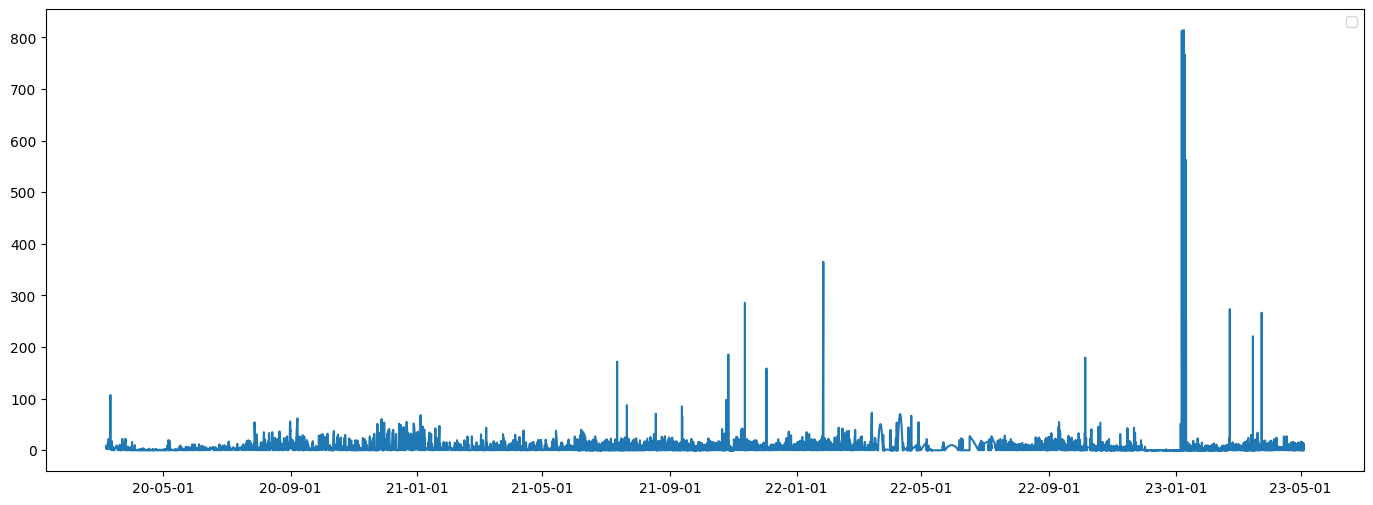

In [7]:
# visualize data 1

plt.figure(figsize=(17, 6))
plt.plot(df1.index, df1['b210_diff'])

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

In [8]:
# Normalization 
df = df1
df['Date'] = df.index
temp_df = df1.drop(['Date'], axis = 1)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(temp_df)
temp_df = pd.DataFrame(scaled_data, columns = temp_df.columns, index = temp_df.index)

temp_df['Date'] = df1["Date"]

In [9]:
df1.columns

Index(['b210_pt', 'b055_raw', 'b103_raw', 'b166_raw', 'b002_raw', 'b084_raw',
       'b081_raw', 'b210_cal', 'b055_cal', 'b103_cal', 'b166_cal', 'b002_cal',
       'b084_cal', 'b081_cal', 'b210_diff', 'b055_diff', 'b103_diff',
       'b166_diff', 'b002_diff', 'b084_diff', 'b081_diff', 'Date'],
      dtype='object')

In [10]:
temp_df

,b210_pt,b055_raw,b103_raw,b166_raw,b002_raw,b084_raw,b081_raw,b210_cal,b055_cal,b103_cal,...,b084_cal,b081_cal,b210_diff,b055_diff,b103_diff,b166_diff,b002_diff,b084_diff,b081_diff,Date
Date/Time,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.240938,-0.933752,...,-0.612439,-0.736053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-01 00:00:00
2020-01-01 01:00:00,NaN,-0.041058,-0.259023,-0.754141,-1.436342,-0.334530,NaN,NaN,0.216093,-0.933752,...,-0.712290,-0.753168,NaN,-0.602259,-0.343562,-0.437904,-0.491501,-0.367021,NaN,2020-01-01 01:00:00
2020-01-01 02:00:00,NaN,-0.118198,-0.259023,-0.653393,-1.532757,-0.380535,NaN,NaN,0.203832,-0.933752,...,-0.919181,-0.835382,NaN,-0.567738,-0.343562,-0.542616,-0.388638,-0.469540,NaN,2020-01-01 02:00:00
2020-01-01 03:00:00,NaN,-0.187217,-0.296385,-0.678580,-1.522045,-0.380535,NaN,NaN,0.200694,-0.933752,...,-0.799553,-0.814459,NaN,-0.524841,-0.380360,-0.581433,-0.455692,-0.383445,NaN,2020-01-01 03:00:00
2020-01-01 04:00:00,NaN,-0.122258,-0.296385,-0.736510,-1.532757,-0.395870,NaN,NaN,0.192242,-0.933752,...,-0.960397,-0.690741,NaN,-0.582703,-0.380360,-0.381766,-0.443885,-0.457770,NaN,2020-01-01 04:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-05-03 19:00:00,-0.113632,-0.645995,0.039872,-0.038834,-0.761433,0.209862,-0.695477,-0.004736,NaN,-0.217662,...,0.278273,-1.070869,-0.205055,NaN,-0.262945,0.392646,-0.480377,-0.202943,-0.586832,2023-05-03 19:00:00
2023-05-03 20:00:00,0.622723,-0.645995,0.002510,-0.167287,-0.857849,0.209862,-0.733728,-0.046993,NaN,-0.348914,...,0.263465,-1.085780,-0.001194,NaN,-0.308370,-0.122069,-0.302234,-0.213600,-0.602944,2023-05-03 20:00:00
2023-05-03 21:00:00,-0.429213,-0.645995,-0.016171,-0.331002,-0.868561,0.194527,-0.751659,-0.212736,NaN,-0.678849,...,0.274761,-1.099811,-0.236870,NaN,-0.264060,-0.534834,-0.204803,-0.190011,-0.626057,2023-05-03 21:00:00


In [11]:
### Trand & Seasonality 

# Prophet: https://blog.wadiz.kr/prophet%EC%9D%84-%EC%9D%B4%EC%9A%A9%ED%95%98%EC%97%AC-%EC%9B%94%EA%B0%84-%ED%8E%80%EB%94%A9-%EA%B8%88%EC%95%A1-%EC%98%88%EC%B8%A1%ED%95%98%EA%B8%B0/
model1 = Prophet()
model2 = Prophet()

# Define dataframe for prophet

prof1 = temp_df[["Date", "b210_cal"]]
prof1.rename(columns={'Date': 'ds', 'b210_cal': 'y'}, inplace=True)
prof2 = temp_df[["Date", "b055_cal"]]
prof2.rename(columns={'Date': 'ds', 'b055_cal': 'y'}, inplace=True)

# Train model
model1.fit(prof1)
model2.fit(prof2)

# Generate dataframe for prediction
future1 = model1.make_future_dataframe(periods=2)  
future2 = model2.make_future_dataframe(periods=2)  

# Prediction
forecast1 = model1.predict(future1)
forecast2 = model2.predict(future2)

# Decompose date
decomposed_data_b210_pt = forecast1[['ds', 'trend', 'daily', 'weekly', 'yearly']]
decomposed_data_b055_raw = forecast2[['ds', 'trend', 'daily', 'weekly', 'yearly']]

print(decomposed_data_b210_pt)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_10409/2296203706.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prof1.rename(columns={'Date': 'ds', 'b210_cal': 'y'}, inplace=True)
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_10409/2296203706.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prof2.rename(columns={'Date': 'ds', 'b055_cal': 'y'}, inplace=True)
10:34:00 - cmdstanpy - INFO - Chain [1] start processing
10:34:09 - cmdstanpy - INFO - Chain [1] done processing
10:34:11 - cmdstanpy - INFO - Chain [1] start processing
10:34:22 - cmdstanpy - INFO - Chain [1] done processing


                       ds     trend     daily    weekly    yearly
0     2020-03-07 08:00:00 -0.017526 -0.048205 -0.011033 -0.137684
1     2020-03-07 09:00:00 -0.017524 -0.016938 -0.011510 -0.138169
2     2020-03-07 10:00:00 -0.017521  0.027993 -0.011683 -0.138651
3     2020-03-07 11:00:00 -0.017518  0.074662 -0.011554 -0.139132
4     2020-03-07 12:00:00 -0.017515  0.116856 -0.011131 -0.139610
...                   ...       ...       ...       ...       ...
27244 2023-05-03 21:00:00  0.144090 -0.112794 -0.031733 -0.049830
27245 2023-05-03 22:00:00  0.144067 -0.101978 -0.031357 -0.049798
27246 2023-05-03 23:00:00  0.144045 -0.091365 -0.030667 -0.049767
27247 2023-05-04 23:00:00  0.143501 -0.091365  0.038330 -0.049285
27248 2023-05-05 23:00:00  0.142957 -0.091365  0.005548 -0.049159

[27249 rows x 5 columns]


In [12]:
# 예측 결과에서 추세, 계절성 및 예측값 추출
trend1 = forecast1['trend']
seasonality1 = forecast1[['daily', 'weekly', 'yearly']]
yhat1 = forecast1['yhat']

# 불규칙성 계산 (원래 값에서 추세와 계절성을 빼면 불규칙성을 얻을 수 있음)
residual = prof1['y'] - (trend1 + seasonality1.sum(axis=1))
predicted_part = trend1 + seasonality1.sum(axis=1)
# predicted_part['ds'] = future1['ds'][-len(predicted_part):].values
prof1 = prof1.reset_index()

# 복원
reconstructed_data = pd.concat([prof1['ds'], predicted_part], axis=1)
reconstructed_data.rename(columns={0: 'y'}, inplace=True)

### Reconstruction 2 (b055)
trend2 = forecast2['trend']
seasonality2 = forecast2[['daily', 'weekly', 'yearly']]
yhat2 = forecast2['yhat']

# 불규칙성 계산 (원래 값에서 추세와 계절성을 빼면 불규칙성을 얻을 수 있음)
residual2 = prof2['y'] - (trend2 + seasonality2.sum(axis=1))
predicted_part2 = trend2 + seasonality2.sum(axis=1)
# predicted_part['ds'] = future1['ds'][-len(predicted_part):].values
prof2 = prof2.reset_index()

# 복원
reconstructed_data2 = pd.concat([prof2['ds'], predicted_part2], axis=1)
reconstructed_data2.rename(columns={0: 'y'}, inplace=True)

In [13]:
reconstructed_data

,ds,y
0,2020-01-01 00:00:00,-0.214449
1,2020-01-01 01:00:00,-0.184140
2,2020-01-01 02:00:00,-0.139863
3,2020-01-01 03:00:00,-0.093542
4,2020-01-01 04:00:00,-0.051399
...,...,...
29251,2023-05-03 19:00:00,NaN
29252,2023-05-03 20:00:00,NaN
29253,2023-05-03 21:00:00,NaN
29254,2023-05-03 22:00:00,NaN


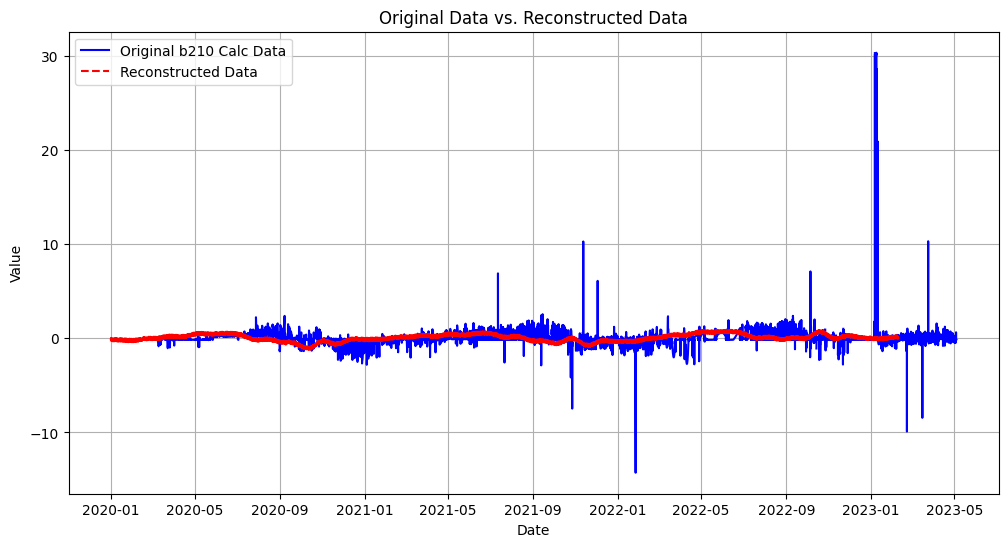

In [14]:
# 원래 데이터와 복원된 데이터 시각화 (original and normal)
plt.figure(figsize=(12, 6))
plt.plot(prof1['ds'], prof1['y'], label='Original b210 Calc Data', color='blue', linestyle='-')
plt.plot(reconstructed_data['ds'], reconstructed_data['y'], label='Reconstructed Data', color='red', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Original Data vs. Reconstructed Data')
plt.legend()
plt.grid(True)
plt.show()

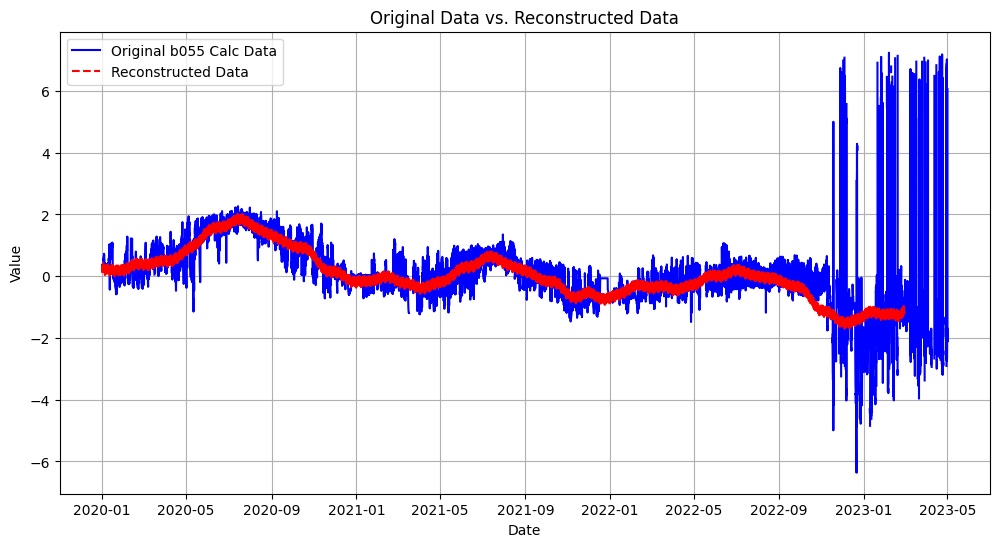

In [15]:
# 원래 데이터와 복원된 데이터 시각화 (original and normal)
plt.figure(figsize=(12, 6))
plt.plot(prof2['ds'], prof2['y'], label='Original b055 Calc Data', color='blue', linestyle='-')
plt.plot(reconstructed_data2['ds'], reconstructed_data2['y'], label='Reconstructed Data', color='red', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Original Data vs. Reconstructed Data')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# temp = prof1
# temp[temp.y > 3] = None

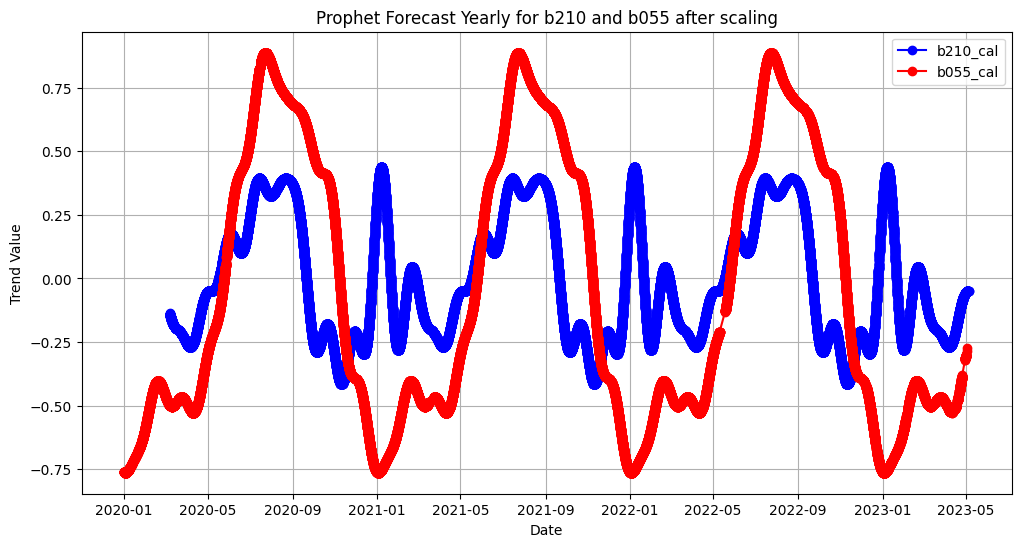

In [17]:
# Visualization Prediction Result after scaling
plt.figure(figsize = (12, 6))
plt.plot(forecast1['ds'], forecast1['yearly'], label='b210_cal', color='blue', linestyle='-', marker='o')
plt.plot(forecast2['ds'], forecast2['yearly'], label='b055_cal', color='red', linestyle='-', marker='o')
plt.xlabel('Date')
plt.ylabel('Trend Value')
plt.title('Prophet Forecast Yearly for b210 and b055 after scaling')
plt.legend()
plt.grid(True)
plt.show()

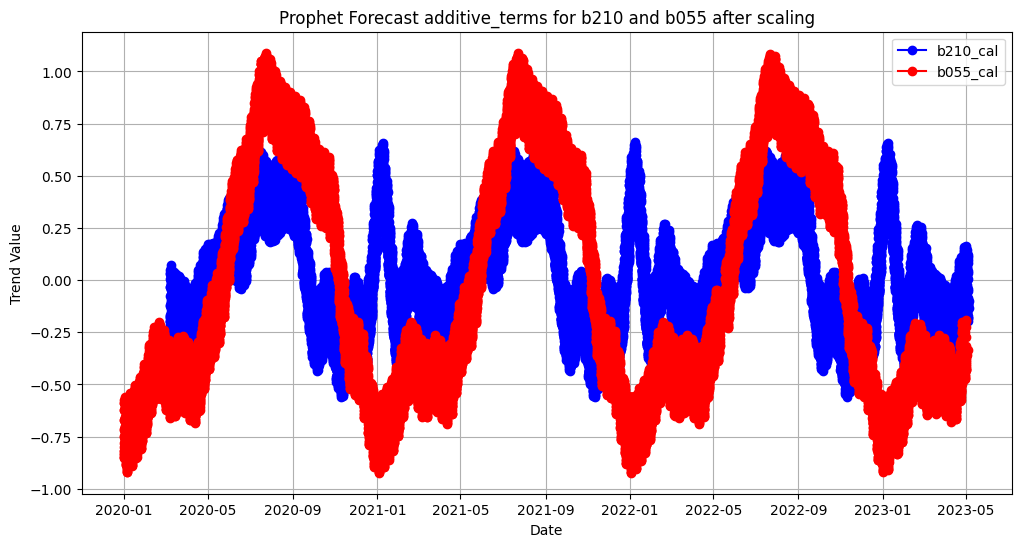

In [18]:
# Visualization Prediction Result after scaling
plt.figure(figsize = (12, 6))
plt.plot(forecast1['ds'], forecast1['additive_terms'], label='b210_cal', color='blue', linestyle='-', marker='o')
plt.plot(forecast2['ds'], forecast2['additive_terms'], label='b055_cal', color='red', linestyle='-', marker='o')
plt.xlabel('Date')
plt.ylabel('Trend Value')
plt.title('Prophet Forecast additive_terms for b210 and b055 after scaling')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# Plotting with Actual and predicted values.
# https://github.com/sivabalachandran/house-preice-prediction-prophet/blob/master/Model.ipynb
plotly = plot_plotly(model1, forecast1)
plotly.update_layout(showlegend=True)

/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/prophet/plot.py:72: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result

/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/prophet/plot.py:73: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



[[<matplotlib.lines.Line2D at 0x28f81faf0>],

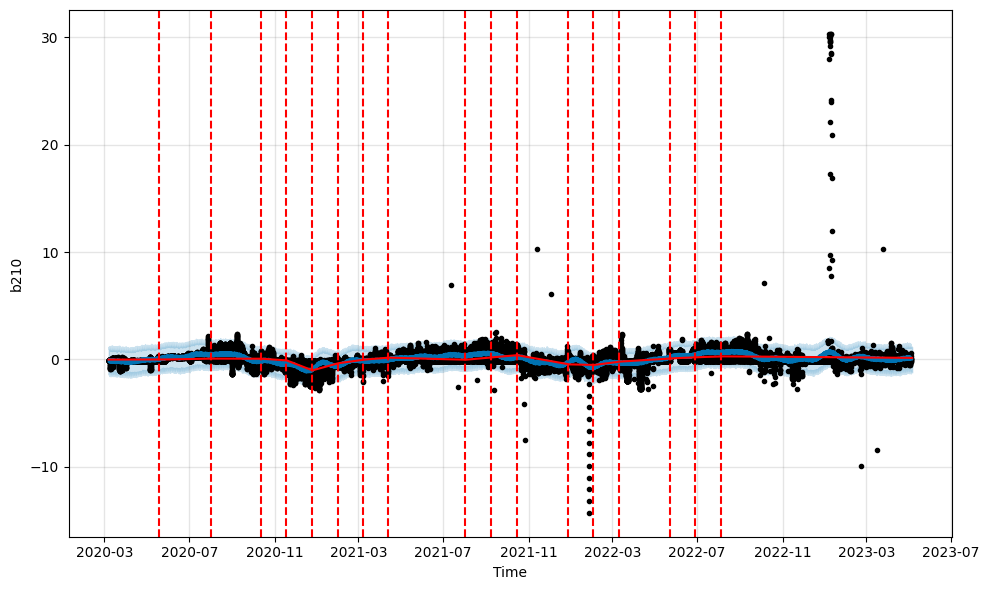

In [20]:
# Trend with change points.
plot = model1.plot(forecast1, xlabel='Time', ylabel='b210')
add_changepoints_to_plot(plot.gca(), model1, forecast1)

### ID-CNN & LSTM-AE

In [21]:
reconstructed_data.index = reconstructed_data['ds']
reconstructed_data = reconstructed_data.drop(['ds'], axis = 1)

In [23]:
prof1.index = prof1['ds']
prof1 = prof1.drop(['Date/Time', 'ds'], axis = 1)

In [25]:
# Input
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 
num_samples = len(signal_train) 

# 추세와 계절성 데이터 추출 (이전에 설명한 방법 사용)
input_layer = Input(shape=(num_samples, 1))
conv1 = Conv1D(filters=16, kernel_size=5, activation='relu')(input_layer)
maxpool1 = MaxPooling1D(pool_size=2)(conv1)
conv2 = Conv1D(filters=32, kernel_size=5, activation='relu')(maxpool1)
maxpool2 = MaxPooling1D(pool_size=2)(conv2)
flatten = Flatten()(maxpool2)

# 추세 및 계절성 패턴을 추출하는 모델 생성
model = keras.Model(inputs = input_layer, outputs = flatten)
model.compile(optimizer = 'adam', loss = 'mse')

train_data = signal_train.reshape(1, len(signal_train), 1)
model.fit(train_data, train_data, epochs=50, batch_size=16, validation_data=(train_data, train_data))
val_data = signal_valid.reshape(1, num_samples - len(signal_valid), 1)
predictions = model.predict(val_data)

# LSTM Autoencoder 모델 정의
encoding_dim = 64
timesteps = num_samples
features = 1

Epoch 1/50


ValueError: in user code:

    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1377, in train_function  *
        return step_function(self, iterator)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1360, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1349, in run_step  **
        outputs = model.train_step(data)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1127, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1185, in compute_loss
        return self.compiled_loss(
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/si

In [26]:
num_series = 1
epochs = 10
window_size = 10

# 1D CNN (extract trend & seasonality)
def extract_trend_seasonality(series, window_size):
    model = Sequential([
        Conv1D(filters = 32, kernel_size = window_size, activation = 'relu', input_shape = (None, 1)),
        MaxPooling1D(pool_size = 2),
        LSTM(50, activation = 'relu'),
        Dense(1)
    ])

    model.compile(optimizer = 'adam', loss = 'mse')
    series = np.array(series).reshape((num_series, -1, 1))
    model.fit(series, series, epochs = epochs)

    # 추출된 트렌드 및 시즌얼리 데이터
    trend_seasonality = model.predict(series)
    return trend_seasonality

# LSTM을 통한 훈련
def train_lstm_on_trend_seasonality(trend_seasonality):
    model = Sequential([
        LSTM(50, activation='relu', input_shape = (None, 1), return_sequences = True),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mae')
    trend_seasonality = np.array(trend_seasonality).reshape((num_series, -1, 1))
    model.fit(trend_seasonality, trend_seasonality, epochs = epochs)

    return model

# 트렌드 및 시즌얼리 데이터 추출
trend_seasonality = extract_trend_seasonality(signal_train, window_size)

# LSTM을 통한 훈련
lstm_model = train_lstm_on_trend_seasonality(trend_seasonality)


Epoch 1/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 2/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 3/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 4/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 5/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 6/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 7/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 8/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 9/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 10/10
1/1 [==============================] - 0s 436ms/step
Epoch 1/10
1/1 [==============================] - 1s 607ms/step - loss: 0.0015
Epoch 2/10
1/1 [==============================] - 0s 3ms/step - loss: 6.6912e-06
Epoch 3/10
1/1 [==============================] - 0s 3ms/step - loss: 0.0014
Epoch 4/10
1/1

In [88]:
# 예측 및 시각화
signal_test[np.isnan(signal_test)] = 0
test_series = signal_test
test_series = np.array(test_series).reshape((-1, 1))

predicted_trend_seasonality = lstm_model.predict(test_series.reshape((1, -1, 1)))

1/1 [==============================] - 1s 662ms/step


In [84]:
predicted_trend_seasonality

array([[0.00475079]], dtype=float32)

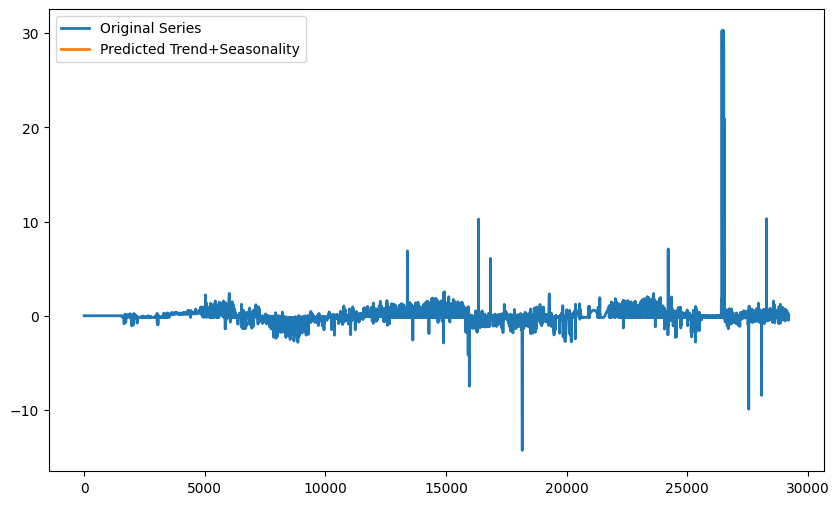

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(test_series[:, :], label='Original Series', linewidth=2)
plt.plot(predicted_trend_seasonality[:, :], label='Predicted Trend+Seasonality', linewidth=2)
plt.legend()
plt.show()

In [61]:
predicted_trend_seasonality = lstm_model.predict(test_series)

1/1 [==============================] - 1s 699ms/step


### LSTM-AE with reconstructed_data as normal

In [58]:
reconstructed_data.index = pd.to_datetime(reconstructed_data['ds'])
reconstructed_data = reconstructed_data.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/1548268338.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [59]:
# orignal data
prof1.index = pd.to_datetime(prof1['ds'])
prof1 = prof1.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/2715252278.py:3: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [60]:
### split data
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 

# set window length
window_length = 12 * 2

train_windows = []

for window_start in range(0, len(signal_train) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_train[window_range])
    train_windows.append(window)
    
# shape of training set
x_train = np.array(train_windows)
x_train.shape

valid_windows = []
for window_start in range(0, len(signal_valid) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_valid[window_range])
    valid_windows.append(window)
    
# shape of validation set
x_valid = np.array(valid_windows)
x_valid.shape

test_windows = []

for window_start in range(0, len(signal_test) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_test[window_range])
    test_windows.append(window)

In [79]:
### LSTM Auto-Encoder Model
# optimizer list: adam, adamW, adadelta, adagrad, adamax, nadam

input_length = window_length
input_dim = 1 # number of variable
hidden_dim = 5
batch_size = 64
epochs = 100
opt = keras.optimizers.Adam(learning_rate=0.0005)

def model():
    m = Sequential()
    m.add(LSTM(units=4 * hidden_dim, activation='relu', input_shape=(input_length, input_dim), return_sequences=True))
    m.add(Dropout(rate=0.3))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=4 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(Dense(1))
    return m

# https://gooopy.tistory.com/90
m = model()
m.compile(loss='mse', optimizer=opt) # adam to rmsprop
m.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 24, 20)            1760      
                                                                 
 dropout_6 (Dropout)         (None, 24, 20)            0         
                                                                 
 lstm_7 (LSTM)               (None, 24, 10)            1240      
                                                                 
 dropout_7 (Dropout)         (None, 24, 10)            0         
                                                                 
 lstm_8 (LSTM)               (None, 24, 5)             320       
                                                                 
 dropout_8 (Dropout)         (None, 24, 5)             0         
                                                                 
 lstm_9 (LSTM)               (None, 24, 5)            

In [80]:
checkpointer = ModelCheckpoint(filepath = "lstm.autoencoder.weights.best.hdf5", verbose = 1, save_best_only = True)
earlystopper = EarlyStopping(monitor = 'val_loss', patience = 10, verbose = 0)
tbCallBack = TensorBoard(log_dir = './lstm.autoencoder.tb.graph', histogram_freq = 0, write_graph = True, write_images = True)

In [81]:
history = m.fit(x_train, x_train, batch_size = batch_size, epochs = epochs, validation_data = (x_valid, x_valid), 
                callbacks = [checkpointer, earlystopper, tbCallBack], verbose = 0).history


Epoch 1: val_loss improved from inf to 0.00350, saving model to lstm.autoencoder.weights.best.hdf5

Epoch 2: val_loss did not improve from 0.00350

Epoch 3: val_loss did not improve from 0.00350

Epoch 4: val_loss did not improve from 0.00350

Epoch 5: val_loss did not improve from 0.00350

Epoch 6: val_loss did not improve from 0.00350

Epoch 7: val_loss did not improve from 0.00350

Epoch 8: val_loss did not improve from 0.00350

Epoch 9: val_loss did not improve from 0.00350

Epoch 10: val_loss did not improve from 0.00350

Epoch 11: val_loss did not improve from 0.00350


In [82]:
pred_x_valid = m.predict(x_valid)

67/67 [==============================] - 1s 5ms/step


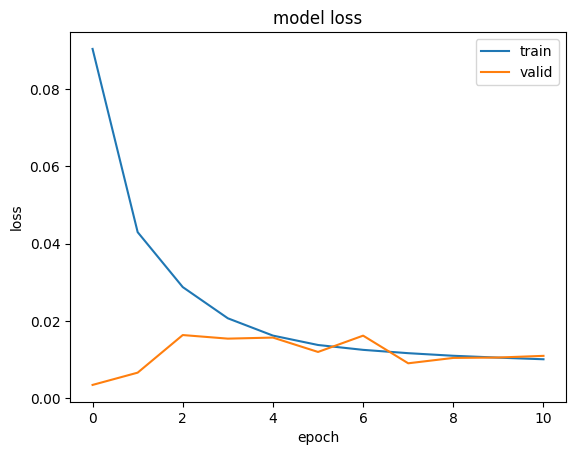

In [83]:
# summarize history for loss
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='best')
plt.show()

In [84]:
x_test = np.array(test_windows)
pred_x_test = m.predict(x_test)

913/913 [==============================] - 5s 5ms/step


In [85]:
# calculate error score
all_errors_valid = pd.Series(np.squeeze((x_valid.shape[:-1]) - pred_x_valid.reshape(pred_x_valid.shape[:-1])[:,:]).flatten())
all_errors_test = pd.Series(np.squeeze((x_test.shape[:-1]) - pred_x_test.reshape(pred_x_test.shape[:-1])[:,:]).flatten())

In [86]:
# calculate error score (window)
def sum_abs_errors_window(errors_in_window):
    return np.sum(np.abs(errors_in_window))

errors_test_per_window = np.squeeze(x_test.shape[:-1] -  pred_x_test.reshape(pred_x_test.shape[:-1])[:,:])
sum_abs_errors_window_0 = np.sum(np.abs(errors_test_per_window[0]))
sum_abs_errors_per_window = pd.Series([sum_abs_errors_window(errors_in_window) for errors_in_window in errors_test_per_window])

In [93]:
# Top anomalous windows ranked and get index
pred_outlier_indices = sum_abs_errors_per_window.nlargest(10).index.values

In [94]:
intervel_length = 1

In [95]:
def highlightComaprison(series, index, colorSTR):
    # Create a mask to identify where the Series values equal 4
    for i in range(len(index)):
        val = series[index[i]]
        mask = ((series) == val) 
        
        # Find the start and end indices of each continuous section where the value equals 4
        section_start = mask & ~mask.shift(fill_value=False)
        section_end = mask & ~mask.shift(-1, fill_value=False)
        
        for start, end in zip(section_start[section_start].index, section_end[section_end].index):
            plt.axvspan(start, end, color=colorSTR, alpha = 0.8)

In [96]:
test = pd.Series(signal_test)
test.index = prof1['2020-01-01':'2023-05-01'].index

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/4180722373.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



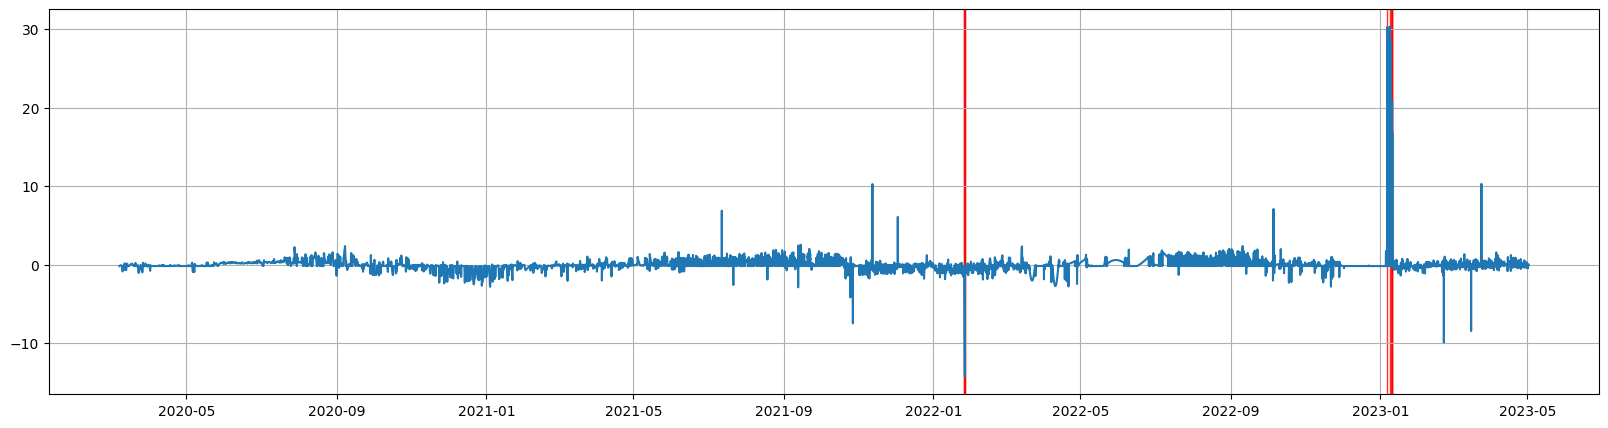

In [97]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(prof1['2020-01-01':'2023-05-01'].index, test)
highlightComaprison(test, pred_outlier_indices, 'red')
plt.grid(True);

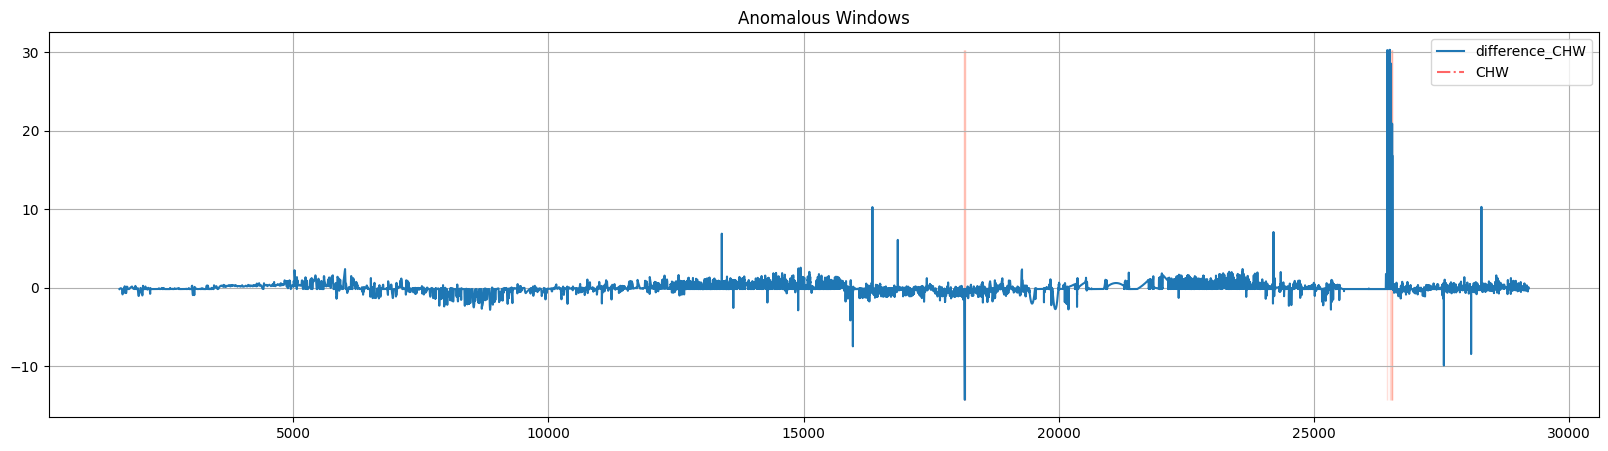

In [98]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(signal_test)
plt.axhline(y=signal_test.mean(), color='r', linestyle='-.', alpha=0.6) # the  horizontal line for mean
plt.axhline(y=signal_test.mean() + signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean + std_dev
plt.axhline(y=signal_test.mean() + 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean + 2 * std_dev
plt.axhline(y=signal_test.mean() - 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean - 2 * std_dev
plt.axhline(y=signal_test.mean() - signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean - std_dev
for w_index in pred_outlier_indices:
    plt.fill_betweenx((np.nanmin(signal_test), np.nanmax(signal_test)), w_index, w_index + intervel_length - 1, alpha=0.2, color='tomato')
plt.title('Anomalous Windows')
plt.legend(["difference_CHW", "CHW"])
plt.grid(True);

In [56]:
### Outlier detection (contain None for spike)

data1 = scaled_df[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]
data1[data1 < -0.1] = None
data1[data1 > 0.1] = None
data1 = data1.fillna(method = "ffill")
data1 = data1.dropna()

# Numerical dataframe
from sklearn.cluster import DBSCAN
model = DBSCAN(eps = 0.001, min_samples = 10).fit(data1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_62669/3009463891.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data1 = data1.fillna(method = "ffill")


In [35]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2'],
      dtype='object')

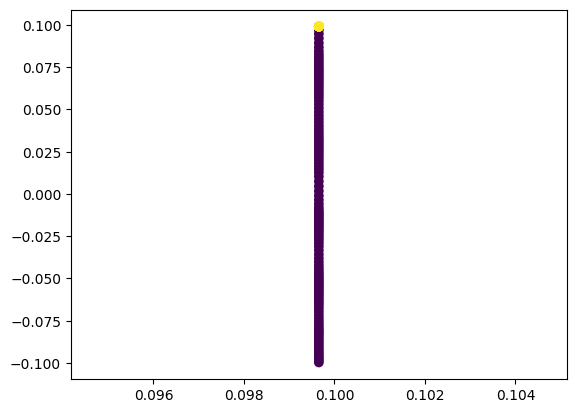

In [38]:
colors = model.labels_
plt.scatter(data1["b084_raw_group2"], data1["b081_raw_group2"], c = colors)

In [39]:
data1[model.labels_ == -1]

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-11-20 19:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.099678
2022-11-20 20:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.098495
2022-11-20 21:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.097326
2022-11-20 22:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.096099
2022-11-20 23:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.094775
...,...,...,...,...,...,...
2022-11-25 13:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.086765
2022-11-25 14:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.089293
2022-11-25 15:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.092072


In [40]:
# GMM 모델 생성
n_clusters = 10  # 클러스터 수를 설정
covariance_type = 'spherical'  # 또는 다른 유형 선택 가능

gmm = GaussianMixture(n_components = n_clusters, covariance_type = covariance_type)
gmm.fit(data1)

# 클러스터 할당
cluster_labels = gmm.predict(data1)

# 결과를 데이터프레임에 추가
data1['Cluster_Label'] = cluster_labels

In [41]:
# Isolation Forest 모델 생성
isolation_forest = IsolationForest(contamination=0.05)  # contamination은 이상치 비율을 나타냅니다

# 모델 훈련
isolation_forest.fit(data1)

# 이상치 여부를 예측 (-1은 이상치, 1은 정상치)
outlier_labels = isolation_forest.predict(data1)

# 결과를 데이터프레임에 추가
data1['Outlier_Label'] = outlier_labels

In [42]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2',
       'Cluster_Label', 'Outlier_Label'],
      dtype='object')

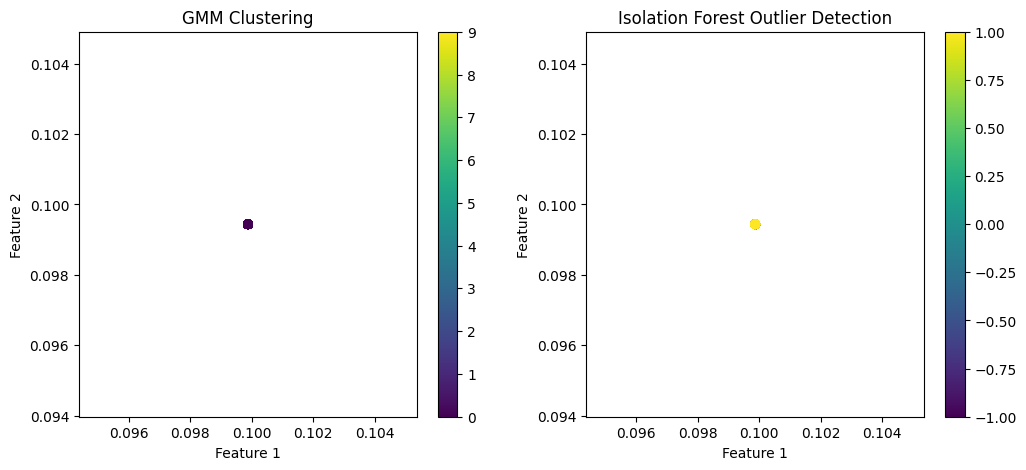

In [44]:
# 클러스터링 결과 및 이상치 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 클러스터링 결과 시각화
scatter1 = ax1.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=cluster_labels, cmap='viridis')
ax1.set_title("GMM Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
fig.colorbar(scatter1, ax=ax1)

# 이상치 탐지 결과 시각화
scatter2 = ax2.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=outlier_labels, cmap='viridis')
ax2.set_title("Isolation Forest Outlier Detection")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter2, ax=ax2)

plt.show()

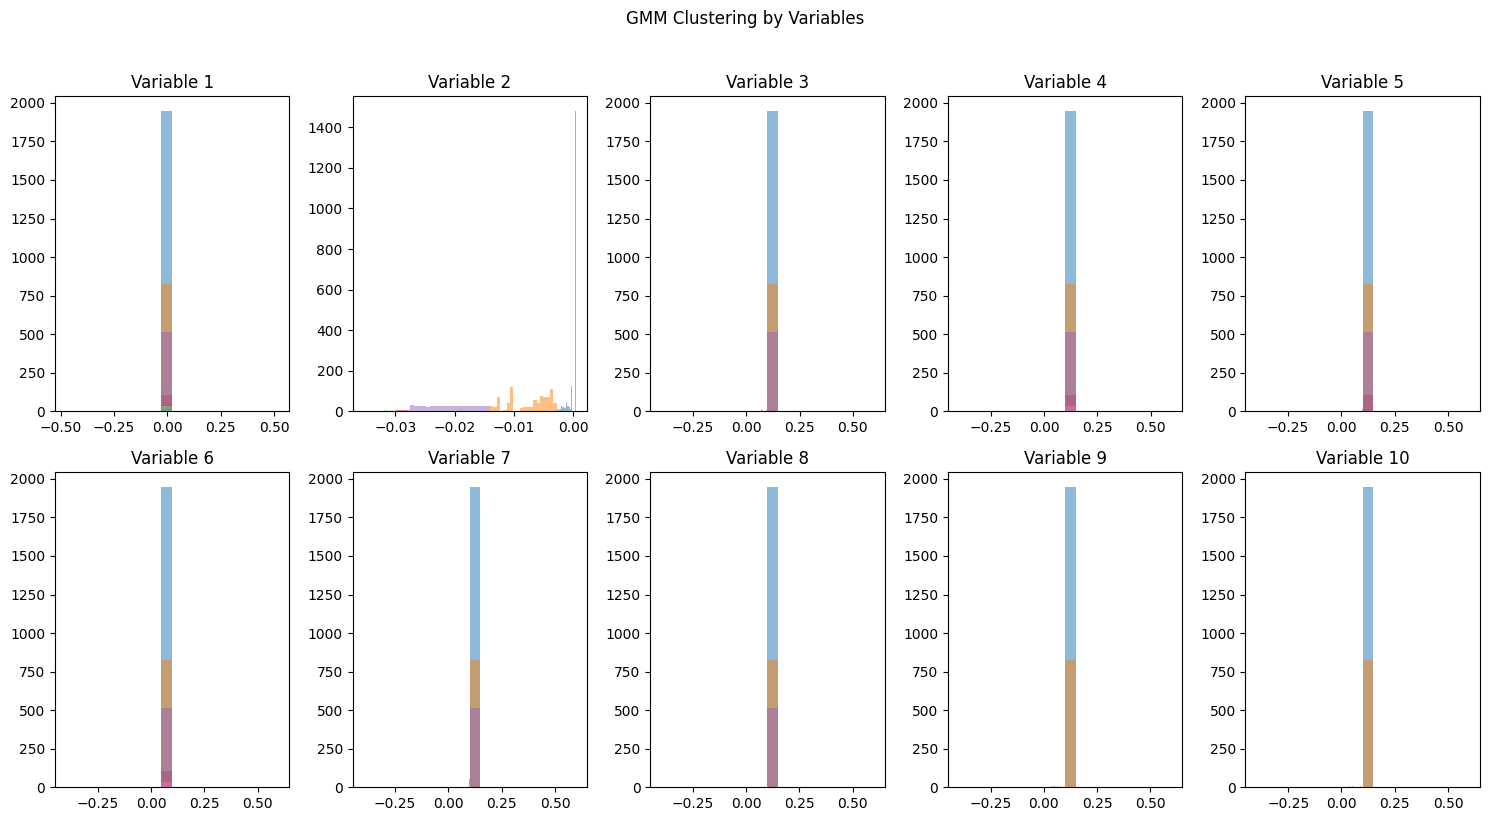

In [103]:
# 클러스터링 결과 시각화
plt.figure(figsize=(15, 8))
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    for i in range(10):  # 10개 변수
        plt.subplot(2, 5, i + 1)
        plt.hist(cluster_data.iloc[:, i], bins = 20, alpha = 0.5, label = f'Cluster {cluster_label + 1}')
        plt.title(f'Variable {i + 1}')
    
plt.suptitle("GMM Clustering by Variables", y = 1.02)
plt.tight_layout()
plt.show()

In [105]:
cluster_data

,b181_raw_group1,b146_raw_group1,b153_raw_group1,b147_raw_group1,b165_raw_group1,b167_raw_group1,b195_raw_group1,b790_raw_group1,b116_raw_group1,b064_raw_group1,Cluster_Label,Outlier_Label
Date/Time,,,,,,,,,,,,
2022-10-11 22:00:00,0.021912,-0.002759,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-11 23:00:00,0.021912,-0.002746,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 00:00:00,0.021912,-0.002732,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 01:00:00,0.021912,-0.002716,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 02:00:00,0.021912,-0.002699,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 18:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 19:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 20:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1


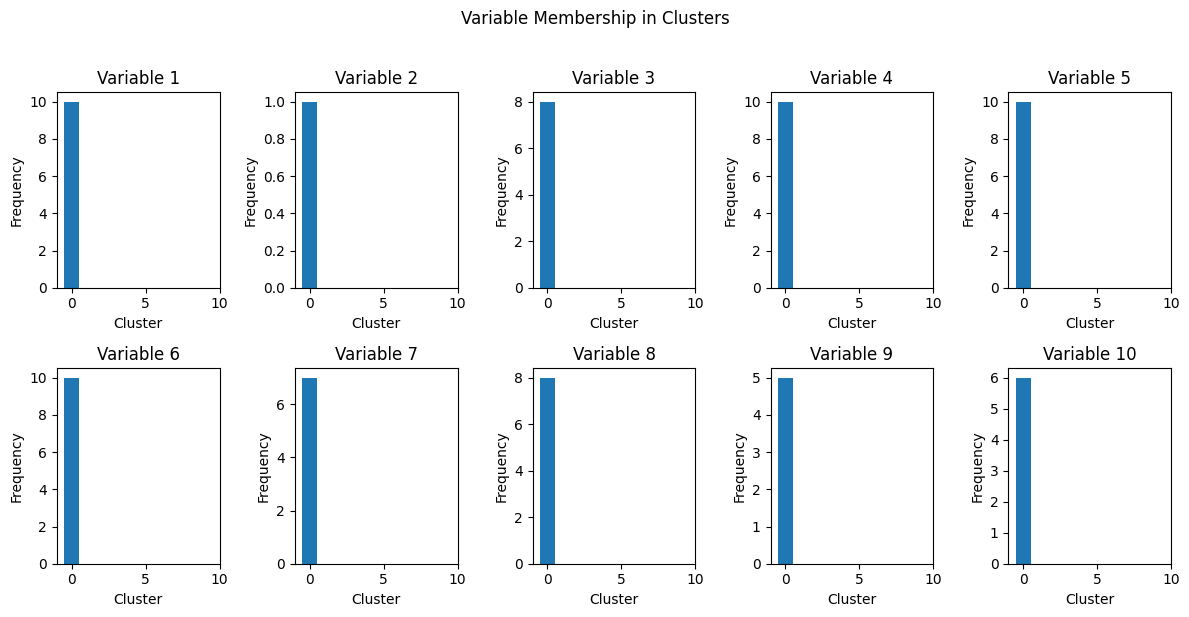

In [107]:
import numpy as np

# 각 변수의 클러스터 소속 확인
variable_cluster_labels = np.zeros((10, n_clusters))  # 변수의 개수 x 클러스터 수
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    cluster_data = cluster_data.drop(['Cluster_Label', "Outlier_Label"], axis = 1)
    variable_cluster_labels[:, cluster_label] = np.mean(cluster_data, axis=0)


# 변수별 클러스터 소속 시각화
plt.figure(figsize=(12, 6))
for i in range(10):  # 10개 변수
    plt.subplot(2, 5, i + 1)
    counts, bins, _ = plt.hist(variable_cluster_labels[i], bins=range(n_clusters + 1), align='left')
    plt.title(f'Variable {i + 1}')
    plt.xlabel('Cluster')
    plt.ylabel('Frequency')
    
plt.suptitle("Variable Membership in Clusters", y=1.02)
plt.tight_layout()
plt.show()


### Generate NAN and Impute GAN (pilot)

In [79]:
data1 = data1.reset_index()
# data1 = data1.drop(['Index'], axis = 1)

In [ ]:
# 결측값 생성

num_points = len(data1)
num_variables = 6
missing_rate = 0.2
for column in df.columns:
    num_missing = int(num_points * missing_rate)
    missing_indices = np.random.choice(num_points, num_missing, replace=False)
    data1.loc[missing_indices, column] = np.nan

In [87]:
data1.index = data1["Date/Time"]
data1 = data1.drop(['Date/Time', "index"], axis = 1)

# Extract data with pt
filtered_columns = [col for col in data1.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
data1 = data1[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [111]:
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
data1.head()

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-04-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-01 01:00:00,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2022-04-01 02:00:00,0.0,0.000058,0.000281,NaN,NaN,NaN
2022-04-01 03:00:00,0.0,0.000035,0.000268,0.000308,NaN,NaN
2022-04-01 04:00:00,0.0,NaN,NaN,0.000298,NaN,NaN


In [91]:
data1 = data1.reset_index()
data1 = data1.drop(['Date/Time'], axis = 1)

In [93]:
data1

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2,0.0,0.000058,0.000281,NaN,NaN,NaN
3,0.0,0.000035,0.000268,0.000308,NaN,NaN
4,0.0,NaN,NaN,0.000298,NaN,NaN
...,...,...,...,...,...,...
6594,0.0,0.000035,0.000287,NaN,0.000000,0.000426
6595,0.0,NaN,NaN,0.000286,NaN,NaN
6596,0.0,NaN,0.000265,0.000288,0.000012,0.000416
6597,NaN,NaN,0.000216,NaN,0.000000,0.000435


In [116]:
# 데이터프레임을 PyTorch 텐서로 변환
real_data = torch.FloatTensor(data1.dropna().values)

In [122]:
# Generator 모델 정의
class Generator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.fc(x)

# Discriminator 모델 정의
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super(Discriminator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.fc(x)

In [128]:
# Generator와 Discriminator 모델 초기화
input_dim = 32
output_dim = num_variables
generator = Generator(input_dim, output_dim)
discriminator = Discriminator(output_dim)

# 손실 함수 및 옵티마이저 정의
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [134]:
# GAN 모델 훈련
num_epochs = 100
batch_size = 32

for epoch in range(num_epochs):
    num_batches = real_data.shape[0] // batch_size
    for _ in range(num_batches):
        noise = torch.randn(batch_size, input_dim)
        generated_data = generator(noise)
        real_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        fake_labels = torch.zeros((batch_size, 1), dtype=torch.float32)

        # Discriminator 훈련
        optimizer_d.zero_grad()
        real_output = discriminator(real_data[:batch_size])
        fake_output = discriminator(generated_data)
        discriminator_loss_real = criterion(real_output, real_labels)
        discriminator_loss_fake = criterion(fake_output, fake_labels)
        discriminator_loss = discriminator_loss_real + discriminator_loss_fake
        discriminator_loss.backward(retain_graph=True)
        optimizer_d.step()

        # Generator를 통한 GAN 훈련
        optimizer_g.zero_grad()
        gan_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        gan_output = discriminator(generated_data)
        gan_loss = criterion(gan_output, gan_labels)
        gan_loss.backward()
        optimizer_g.step()

    print(f'Epoch {epoch}, D Loss: {discriminator_loss.item()}, G Loss: {gan_loss.item()}')


Epoch 0, D Loss: 1.3854780197143555, G Loss: 0.6327202320098877
Epoch 1, D Loss: 1.3908488750457764, G Loss: 0.6290866136550903
Epoch 2, D Loss: 1.3863091468811035, G Loss: 0.6368914246559143
Epoch 3, D Loss: 1.3897672891616821, G Loss: 0.6354539394378662
Epoch 4, D Loss: 1.3817918300628662, G Loss: 0.6448863744735718
Epoch 5, D Loss: 1.3989853858947754, G Loss: 0.6333292722702026
Epoch 6, D Loss: 1.372666358947754, G Loss: 0.6603043675422668
Epoch 7, D Loss: 1.3731648921966553, G Loss: 0.6610397100448608
Epoch 8, D Loss: 1.3767998218536377, G Loss: 0.6590506434440613
Epoch 9, D Loss: 1.3822531700134277, G Loss: 0.6567761898040771
Epoch 10, D Loss: 1.379887342453003, G Loss: 0.6593412160873413
Epoch 11, D Loss: 1.3736572265625, G Loss: 0.6676796078681946
Epoch 12, D Loss: 1.3731087446212769, G Loss: 0.6703320145606995
Epoch 13, D Loss: 1.3778290748596191, G Loss: 0.6668186783790588
Epoch 14, D Loss: 1.3695826530456543, G Loss: 0.6758610606193542
Epoch 15, D Loss: 1.371976613998413, G L

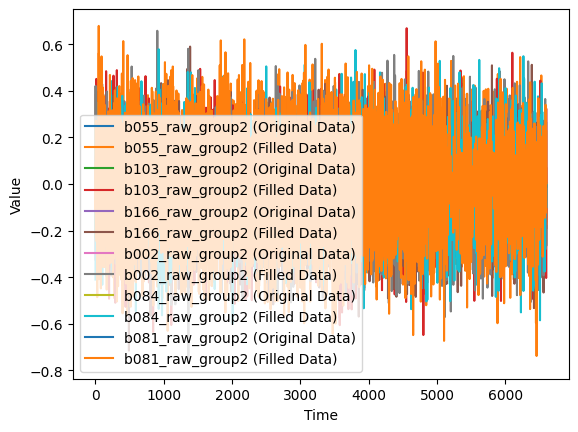

In [136]:
# 결측값을 GAN을 사용하여 채우기
missing_data = data1.copy()
for column in missing_data.columns:
    missing_indices = missing_data[column].isna()
    num_missing = missing_indices.sum()
    noise = torch.randn(num_missing, input_dim)
    generated_values = generator(noise).detach().numpy()
    missing_data.loc[missing_indices, column] = generated_values.flatten()[:num_missing]

# 결과를 시각화
for column in data1.columns:
    plt.plot(data1[column], label=f'{column} (Original Data)')
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

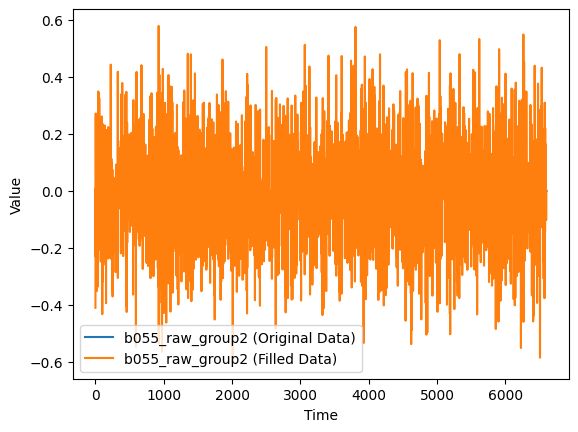

In [148]:
# 결과를 시각화

plt.plot(data1["b084_raw_group2"], label=f'{column} (Original Data)')
plt.plot(missing_data["b084_raw_group2"], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

ValueError: x and y must be the same size

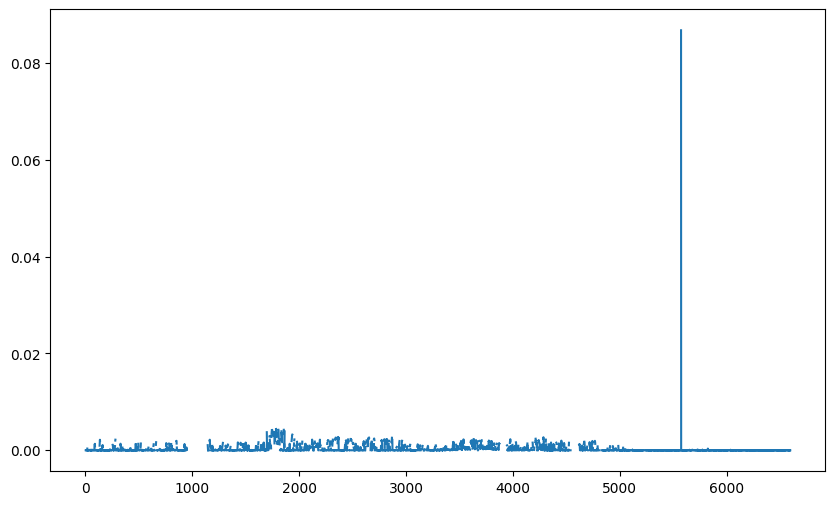

In [141]:
# 결과를 시각화
for column in data1.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(data1[column], label=f'{column} (Original Data)')
    
    # 결측값인 지점에 동그라미 표시
    missing_indices = data1[column].isna()
    plt.scatter(missing_indices.index, data1[column][missing_indices], c='r', marker='o', label='Missing Data')
    
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
    
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()